# Vấn đề 3 – Quá sáng (bạc màu)

**Mục tiêu:** áp dụng phương pháp xử lý ảnh cho đúng vấn đề này → train ResNet-18 **3 lần** → so sánh với baseline (không xử lý) → kết luận **cải thiện / không đổi / tệ đi** và **giải thích vì sao**.

**Cách đọc kết quả (quy tắc đặt trước khi chạy, giống mục 2.5.0 của báo cáo):**
- Mỗi cấu hình train **3 lần** (seed 42, 43, 44) để loại bỏ tính ngẫu nhiên của khởi tạo tham số, thứ tự lấy mẫu và flip.
- Δ = (cấu hình) − (baseline) **ghép cặp theo seed**, trung bình 3 seed. CI95: bootstrap 1 000 lần theo cụm `lesion_id`.
- **"CẢI THIỆN rõ" / "TỆ ĐI rõ"** chỉ khi đủ cả ba: |Δ| > std giữa 3 seed của baseline, CI95 không chứa 0, và cả 3 seed cùng dấu. Không đủ → **"không khác biệt rõ"**.
- Chọn cấu hình theo **val**; test chỉ để báo cáo. Không chọn seed hay ảnh "đẹp".

Chạy lần lượt từ trên xuống (Run All). Logic nằm trong `src/`; notebook chỉ gọi hàm và trình bày.

In [1]:
PROBLEM = "qua_sang"
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")                        # chạy từ thư mục gốc repo
sys.path.insert(0, str(Path.cwd()))
import pandas as pd
from IPython.display import display, Markdown
from src.report import notebook_utils as U
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
P = U.PROBLEMS[PROBLEM]
NAMES = ["baseline"] + P["configs"]
print("Vấn đề:", P["name"], "| cấu hình so sánh:", NAMES)

Vấn đề: Quá sáng (bạc màu) | cấu hình so sánh: ['baseline', 'gamma_L_1.5', 'gamma_L_auto']


## 1. Vấn đề (từ EDA, mục 2.2)

- **Hiện tượng:** nền da gần trắng, mất màu ("bạc"), mất vân da và chi tiết vùng sáng; tổn thương nhạt màu có bờ mờ.
- **Đo bằng:** tỉ lệ pixel "trắng bạc" trong vùng nhìn thấy (HSV: V ≥ 235 và S ≤ 40, Ch.4). **Ngưỡng cờ:** > 10% → **302/10 015 ảnh (3,0%)**; nhóm này có 62,2% pixel mức xám ≥ 200 so với 5,1% ở phần còn lại.
- **Liên hệ lỗi CNN (mục 2.8):** lỗi baseline của nhóm cao hơn kỳ vọng theo thành phần lớp ở test (+0,167, CI loại 0); val cùng chiều nhưng CI chứa 0.

In [2]:
fl = pd.read_csv("outputs/eda/image_flags.csv")
sp = pd.concat([pd.read_csv(f"outputs/splits/{s}.csv")[["image_id"]].assign(split=s) for s in ("train_fit", "val", "test")])
d = sp.merge(fl[["image_id", "dx", P["flag"]]], on="image_id")
tab = d.groupby("split")[P["flag"]].agg(["sum", "size"]).rename(columns={"sum": "số ảnh bị cờ", "size": "tổng"})
tab["%"] = (tab["số ảnh bị cờ"] / tab["tổng"] * 100).round(1)
display(tab.loc[["train_fit", "val", "test"]])
display(d[d[P["flag"]] & (d.split == "test")].dx.value_counts().rename("thành phần lớp của nhóm cờ (test)").to_frame().T)

,số ảnh bị cờ,tổng,%
split,,,
train_fit,196,6408,3.1
val,37,1603,2.3
test,69,2004,3.4


dx,nv,mel,bkl,bcc,vasc,akiec
thành phần lớp của nhóm cờ (test),39,14,9,5,1,1


## 2. Áp dụng gì? (Ch.3 biến đổi lũy thừa + Ch.4 hệ màu)

| Cấu hình | Áp cho | Các bước và tham số |
|---|---|---|
| `gamma_L_1.5` | **mọi ảnh** | **biến đổi lũy thừa** s = r^γ với γ = 1,5 trên L\* (chuẩn hóa về [0, 1]), giữ a\*, b\* |
| `gamma_L_auto` | **chỉ ảnh bị cờ "quá sáng"** | γ = ln(t) / ln(m), m = trung vị L\* trong vùng nhìn thấy, t = 66,61 (trung vị L\* của ảnh **không** quá sáng trong `train_fit`), kẹp γ ∈ [1; 3] để chỉ làm tối |

- **Lý do tham số:** γ > 1 nén vùng sáng, kéo dải mức xám cao về giữa → khôi phục chi tiết; đích t lấy từ train_fit (không dùng val/test → không rò rỉ); xử lý trên L\* để không đổi màu.
- **Giả thuyết (viết trước khi train):**
  - **H1:** đưa độ sáng nhóm quá sáng về mức ảnh bình thường giúp CNN thấy chi tiết sắc tố → kỳ vọng cải thiện **trên nhóm quá sáng**.
  - **H2:** gamma cố định cho **mọi ảnh** làm tối cả ảnh bình thường (lệch phân phối) → có nguy cơ hại toàn tập.
  - **H3 (rủi ro):** một phần ảnh "bạc màu" đến từ **bản chất tổn thương** (nhạt, ít sắc tố – EDA 2.2); làm tối mạnh có thể xóa chính dấu hiệu đó.

## 3. Ảnh trước / sau xử lý

Quy tắc chọn ảnh (cố định, không chọn ảnh "đẹp"): trong nhóm bị cờ ∩ `train_fit`, ảnh có chỉ số EDA gần **trung vị**, gần **phân vị 90** và **lớn nhất**. Bảng dưới: chỉ số EDA trước → sau, % ảnh còn vượt ngưỡng, % ảnh bị đổi và ΔE76 (mức đổi màu trung bình mỗi pixel) trên 100 ảnh bị cờ và 100 ảnh đối chứng (`train_fit`, rút ngẫu nhiên seed 42).

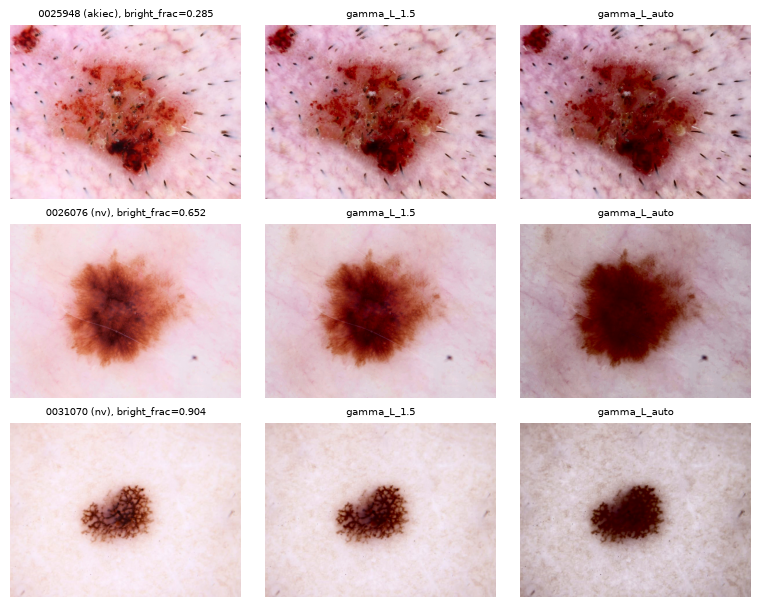

In [3]:
U.fig_before_after(PROBLEM, stem=f"{PROBLEM}_before_after");

In [4]:
display(U.image_effect(PROBLEM))

,cấu_hình,nhóm,n,bright_frac trước (trung vị),bright_frac sau (trung vị),% còn vượt ngưỡng,% ảnh bị đổi,ΔE76 TB
0,gamma_L_1.5,nhóm cờ,100,0.298,0.047,36.0,100.0,8.077
1,gamma_L_1.5,đối chứng,100,0.000,0.000,0.0,100.0,12.091
2,gamma_L_auto,nhóm cờ,100,0.298,0.002,10.0,100.0,15.304
3,gamma_L_auto,đối chứng,100,0.000,0.000,0.0,0.0,0.000


## 4. Áp dụng xử lý ảnh rồi train ResNet-18, 3 lần (seed 42, 43, 44)

- Cấu hình train **giữ nguyên siêu tham số đóng băng** của baseline (mục 2.4): ResNet-18 ImageNet, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WeightedRandomSampler, flip ngang/dọc, chọn epoch theo val macro-F1. **Chỉ thay đổi một yếu tố**: bước xử lý ảnh, áp ở 600×450 trước resize, giống nhau cho train/val/test.
- Tối ưu tốc độ cho RTX 5060 Ti (không đổi siêu tham số): `channels_last` (+26% thông lượng: 1 724 so với 1 364 ảnh/s ở batch 32), batch đánh giá 512, 32 luồng CPU khi tạo cache ảnh. Đo trên máy này: tăng batch train lên 64–512 **không** nhanh hơn (≈ 1 700–1 850 ảnh/s, GPU đã gần hết công suất tính) nên giữ batch 32.
- Thời gian: ≈ 1,5 phút/seed. Baseline (dùng chung cho 4 notebook) chỉ train một lần ở notebook chạy đầu tiên.

In [5]:
# Seed nào đã có kết quả trong outputs/runs_cl/<cấu hình>/seed*/metrics.json thì được đọc lại, không train lại.
# Ctrl+C (hoặc Interrupt kernel) an toàn: chạy lại ô này sẽ tiếp tục từ seed còn thiếu.
for name in NAMES:
    U.train(name)
display(pd.Series(U.run_info(), name="cấu hình lần chạy").to_frame())

[20:35:55] [baseline seed 42] đã có metrics.json -> đọc lại
[20:35:55] [baseline seed 43] đã có metrics.json -> đọc lại
[20:35:55] [baseline seed 44] đã có metrics.json -> đọc lại
[20:35:55] [gamma_L_1.5] nạp ảnh (cache_key=gamma_L_1.5) | split {'train': 6408, 'val': 1603, 'test': 2004} | seed cần train: [42, 43, 44]
[20:36:07] Đọc cache outputs/cache/gamma_L_1.5_224.npy ((10015, 3, 224, 224))
[20:36:23] [gamma_L_1.5 seed 42] epoch  1/20 | train_loss 0.6747 | val_loss 0.6402 | val_F1 0.6063 | val_bAcc 0.6968 | 7.6s
[20:36:27] [gamma_L_1.5 seed 42] epoch  2/20 | train_loss 0.3345 | val_loss 0.6460 | val_F1 0.6435 | val_bAcc 0.7238 | 4.2s
[20:36:31] [gamma_L_1.5 seed 42] epoch  3/20 | train_loss 0.2385 | val_loss 0.6435 | val_F1 0.6537 | val_bAcc 0.6967 | 4.2s
[20:36:35] [gamma_L_1.5 seed 42] epoch  4/20 | train_loss 0.1983 | val_loss 0.6701 | val_F1 0.6626 | val_bAcc 0.6981 | 4.2s
[20:36:39] [gamma_L_1.5 seed 42] epoch  5/20 | train_loss 0.1450 | val_loss 0.5544 | val_F1 0.6908 | val_bA

,cấu hình lần chạy
model,"resnet18 (torchvision, IMAGENET1K_V1), fc -> 7..."
batch_size,32
lr,0.0001
epochs,20
seeds,"[42, 43, 44]"
env,"{'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeFor..."
channels_last,True
eval_batch,512


## 5. So sánh với baseline

### 5.1 Toàn tập: bảng và biểu đồ cột theo từng lần chạy (3 seed)

In [6]:
T = U.comparison(NAMES, "test")
Tv = U.comparison(NAMES, "val")
cols = ["cấu hình", "macro_f1_mean", "macro_f1_std", "macro_f1_per_seed", "macro_f1_delta", "macro_f1_ci_lo",
        "macro_f1_ci_hi", "macro_f1_sign", "macro_f1_verdict", "balanced_acc_delta", "balanced_acc_sign", "balanced_acc_verdict"]
print("TEST (n = 2 004)"); display(T[[c for c in cols if c in T]])
print("VAL (n = 1 603) – tập dùng để chọn cấu hình"); display(Tv[[c for c in cols if c in Tv]])

TEST (n = 2 004)


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.6808,0.0232,0.6783; 0.7052; 0.6590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gamma_L_1.5,0.6811,0.0171,0.6729; 0.7009; 0.6697,0.0003,-0.0252,0.0341,1+/2-,không khác biệt rõ,-0.0098,1+/2-,không khác biệt rõ
2,gamma_L_auto,0.6649,0.0286,0.6758; 0.6325; 0.6866,-0.0159,-0.0442,0.0128,1+/2-,không khác biệt rõ,-0.0389,0+/3-,không khác biệt rõ


VAL (n = 1 603) – tập dùng để chọn cấu hình


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.7274,0.0095,0.7164; 0.7335; 0.7323,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gamma_L_1.5,0.7342,0.0100,0.7278; 0.7290; 0.7458,0.0068,-0.0152,0.0277,2+/1-,không khác biệt rõ,-0.0133,1+/2-,không khác biệt rõ
2,gamma_L_auto,0.7256,0.0177,0.7125; 0.7185; 0.7458,-0.0018,-0.0268,0.0252,1+/2-,không khác biệt rõ,-0.0420,0+/3-,TỆ ĐI rõ


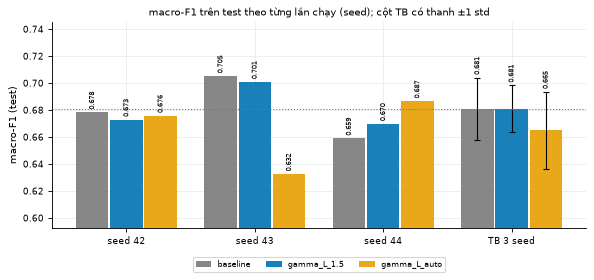

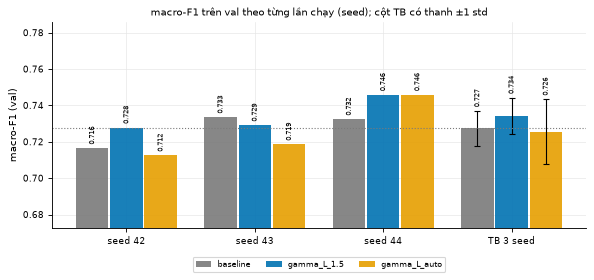

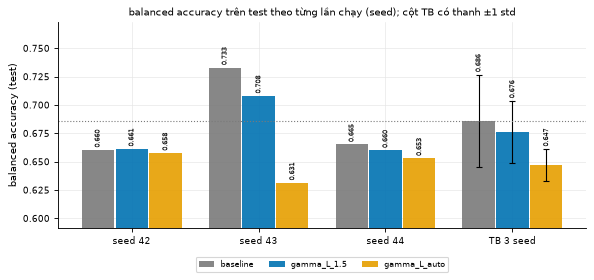

In [7]:
U.fig_seed_bars(NAMES, "test", "macro_f1", stem=f"{PROBLEM}_bars_test_macro_f1")
U.fig_seed_bars(NAMES, "val", "macro_f1", stem=f"{PROBLEM}_bars_val_macro_f1")
U.fig_seed_bars(NAMES, "test", "balanced_acc", stem=f"{PROBLEM}_bars_test_bacc");

### 5.2 Theo lớp và trên chính nhóm ảnh có vấn đề

In [8]:
print("Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)")
display(U.per_class(NAMES, "test"))
print("Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại")
display(pd.concat([U.subgroup(NAMES, P["flag"], "test"), U.subgroup(NAMES, P["flag"], "val")], ignore_index=True))

Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)


,lớp,baseline,gamma_L_1.5,gamma_L_auto
0,akiec,0.712 ± 0.124,0.475 ± 0.115 (-0.237; 0+/3-),0.515 ± 0.189 (-0.197; 0+/3-)
1,bcc,0.754 ± 0.059,0.851 ± 0.020 (+0.097; 3+/0-),0.770 ± 0.065 (+0.016; 2+/1-)
2,bkl,0.686 ± 0.030,0.665 ± 0.020 (-0.021; 1+/2-),0.662 ± 0.075 (-0.024; 2+/1-)
3,df,0.464 ± 0.066,0.536 ± 0.109 (+0.072; 2+/1-),0.435 ± 0.043 (-0.029; 1+/1-)
4,mel,0.580 ± 0.122,0.569 ± 0.111 (-0.011; 1+/2-),0.511 ± 0.124 (-0.069; 1+/2-)
5,nv,0.895 ± 0.022,0.903 ± 0.035 (+0.008; 2+/1-),0.937 ± 0.017 (+0.042; 3+/0-)
6,vasc,0.713 ± 0.155,0.736 ± 0.080 (+0.023; 1+/2-),0.701 ± 0.105 (-0.011; 2+/1-)


Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại


,cấu hình,split,n nhóm,acc nhóm baseline,acc nhóm sau xử lý,Δ acc nhóm,CI95 Δ nhóm,dấu,Δ acc còn lại,DiD,CI95 DiD,sửa (sai→đúng) từng seed,hỏng (đúng→sai) từng seed
0,gamma_L_1.5,test,69,0.6715,0.7005,0.0290,[-0.027; +0.085],2+/0-,-0.0007,0.0297,[-0.028; +0.086],9; 4; 7,5; 4; 5
1,gamma_L_auto,test,69,0.6715,0.6184,-0.0531,[-0.143; +0.041],0+/2-,0.0141,-0.0673,[-0.157; +0.027],5; 5; 9,9; 12; 9
2,gamma_L_1.5,val,37,0.6937,0.7027,0.0090,[-0.069; +0.099],1+/1-,-0.0040,0.0131,[-0.069; +0.100],4; 2; 2,2; 2; 3
3,gamma_L_auto,val,37,0.6937,0.6757,-0.0180,[-0.108; +0.067],0+/2-,0.0162,-0.0342,[-0.122; +0.051],3; 2; 4,4; 3; 4


### 5.3 Kết luận tự động từ số liệu (theo quy tắc ở đầu notebook)

In [9]:
for split, tab in (("test", T), ("val", Tv)):
    for name in P["configs"]:
        display(Markdown("- " + U.verdict_text(tab, name, split)))

- `gamma_L_1.5` (test): macro-F1 0.6811 ± 0.0171, Δ = +0.0003 (CI95 -0.0252; +0.0341), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0098, 1+/2- → không khác biệt rõ.

- `gamma_L_auto` (test): macro-F1 0.6649 ± 0.0286, Δ = -0.0159 (CI95 -0.0442; +0.0128), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0389, 0+/3- → không khác biệt rõ.

- `gamma_L_1.5` (val): macro-F1 0.7342 ± 0.0100, Δ = +0.0068 (CI95 -0.0152; +0.0277), dấu theo seed 2+/1- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0133, 1+/2- → không khác biệt rõ.

- `gamma_L_auto` (val): macro-F1 0.7256 ± 0.0177, Δ = -0.0018 (CI95 -0.0268; +0.0252), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0420, 0+/3- → TỆ ĐI rõ.

## 6. Kết luận và giải thích

**1. Áp dụng gì:** **biến đổi lũy thừa (gamma, γ > 1)** trên kênh L\* (Ch.3, Ch.4). Có hai bản: `gamma_L_1.5` dùng γ = 1,5 cho **mọi ảnh**; `gamma_L_auto` chỉ áp cho **ảnh bị cờ quá sáng**, với γ tự chọn để độ sáng trung vị về mức của ảnh bình thường.

**2. Kết quả: gamma cố định không đổi. Gamma tự động không cải thiện, có dấu hiệu làm tệ đi trên chính nhóm quá sáng, và hướng này lặp lại qua hai lần chạy.**
- `gamma_L_1.5`: test macro-F1 Δ **+0,0003** (CI95 −0,025; +0,034), 1+/2−; val +0,007 (2+/1−). **Không khác biệt rõ.** Trên nhóm quá sáng (69 ảnh test): +0,029 [−0,027; +0,085], 2+/0−.
- `gamma_L_auto`:
  - toàn tập: test Δ −0,016 (1+/2−), val −0,002; balanced accuracy val **"TỆ ĐI rõ"** (−0,042), test −0,039 (0+/3−);
  - **trên nhóm quá sáng: test −0,053** [−0,143; +0,041], 0+/2−; val −0,018. Lần chạy trước: val **−0,099**, 0+/3−;
  - theo lớp: **recall `nv` tăng ở cả test (+0,042) lẫn val (+0,041), cả 3 seed đều tăng**; recall `df` val −0,158 (0+/3−).

**3. Vì sao:**
- **Gamma tự động làm tối rất mạnh đúng các ảnh quá sáng** (mục 3: ΔE76 lớn trên nhóm cờ). Nhiều ảnh "bạc màu" trong HAM10000 là **tổn thương nhạt màu, ít sắc tố**. Độ nhạt có thể chính là một dấu hiệu phân biệt (giả thuyết H3, EDA 2.2). Kéo L\* xuống khiến các tổn thương này trông sẫm như nốt ruồi thông thường, nên mô hình **đẩy chúng về `nv`**: recall `nv` tăng nhất quán, các lớp nhỏ giảm. Trên chính nhóm quá sáng, kết quả xấu đi ở cả hai lần chạy (val lần trước, test lần này).
- **Gamma cố định 1,5 không hại,** dù làm tối mọi ảnh. Một phép biến đổi **giống hệt nhau cho mọi ảnh** chỉ dời phân phối độ sáng một cách đều đặn, và ResNet (có BatchNorm, fine-tune toàn bộ) học bù được. Gamma tự động thì dùng **γ khác nhau cho từng ảnh**, nên làm mất thông tin "ảnh này sáng/nhạt hơn bình thường".
- Phần balanced accuracy giảm còn chịu ảnh hưởng của lưu ý chung (`akiec`).

**4. Hạn chế:** nhóm quá sáng nhỏ (69 ảnh test, 37 ảnh val); γ bị kẹp tối đa 3 nên có thể quá mạnh với ảnh rất sáng; chỉ có 3 seed.

**Lưu ý chung khi đọc balanced accuracy (áp dụng cho cả 4 notebook).** Ở lần chạy này, **cả 8 cấu hình** đều có balanced accuracy val thấp hơn baseline (Δ từ −0,013 đến −0,051), và **cả 8** đều có recall `akiec` test thấp hơn baseline (−0,10 đến −0,32). Điều này xảy ra cả ở những cấu hình chỉ đổi 2,5–3,5% ảnh (`vig_fill`, `vig_crop`, `gamma_L_auto`, `flat_L_s60_cond`), tức hơn 96% ảnh train/test giống hệt baseline. Một phép xử lý chạm vào vài phần trăm ảnh khó có thể tự nó gây ra mức giảm đồng loạt như vậy. Nhiều khả năng **baseline của lần chạy này cao bất thường ở lớp nhỏ `akiec`** (recall test 0,712 ± 0,124; lần chạy trước 0,561), mà balanced accuracy lấy trung bình đều 7 lớp nên rất nhạy với lớp chỉ có 66 ảnh test. Vì vậy các kết luận "TỆ ĐI rõ" **theo balanced accuracy** cần đọc kèm lưu ý này; macro-F1 (chỉ số chính) ít bị ảnh hưởng hơn.
